### The plant
---
Elastic robot joint model


\begin{cases}
J \ddot{\theta} + B (\dot{\theta} - \dot{q}) + K (\theta - q) = u   \quad Motor \\
M \ddot{q} + B (\dot{q} - \dot{\theta}) + K (q - \theta) = 0 \quad Payload
\end{cases}

Transfer function between the joint position and the commanded torque:
$$
P(s)=\frac{Q(s)}{U(s)}=\frac{B s + K}{s^2 \left( J M s^2 + (B J + B M) s + (J K + K M) \right)}
$$

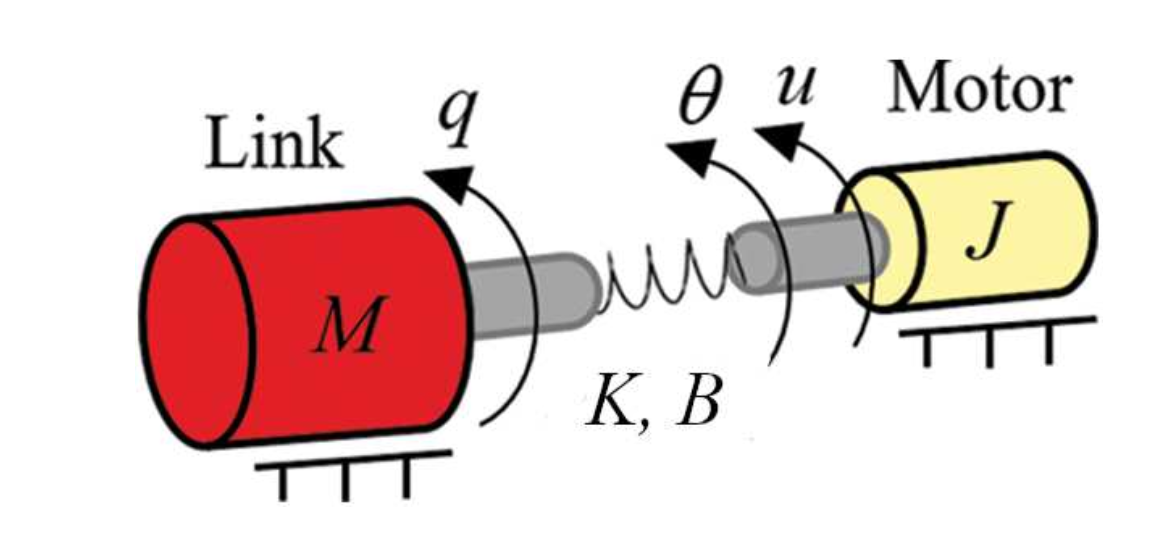

# Specifications
- Steady-state tracking error to unit reference $\leq 0.01$;
- Amplification on the command input of high-frequency noise $n_r$ on the sensor less or equal to −20 dB when the noise frequency is $ω_{nr}\geq 60$ rad/s
- Amplification on the tracking error of high-frequency noise $n_r$ on the sensor less or equal to −20 dB when the noise frequency is $ω_{nr}\geq 60$ rad/s


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control as ct
import slycot as sly
import cvxpy as cp
from itertools import product
import rpc_diism.robust as rb

s=ct.tf('s')

In [2]:
# Plant Parameters

J = 0.01
K = 7.3 
B = 0.04 
M = 0.009


In [3]:
#Frequency range
omega = np.logspace(-2, 4, 1000)

In [4]:
# Plant P
P = ct.tf([B, K],[J*M, B*M+B*J, K*M+K*J,0,0])
display("Plant tf P", P)

'Plant tf P'

TransferFunction(
array([0.04, 7.3 ]),
array([9.000e-05, 7.600e-04, 1.387e-01, 0.000e+00, 0.000e+00]),
outputs=1, inputs=1)

In [5]:
# Natural frequency of the dominant poles of the plant
wp = 27 
epsc = 1e-5

# We move the poles at zero slightly to the left to avoid numerical problems in the computation
# of the H-infinity controller. The algorithm behaves better if the plant is strictly proper and stable.
sc =s+wp*epsc
Pc = (K+B*sc)/(sc**4*(J*M)+sc**3*((M*B+B*J))+sc**2*(M*K+K*J))

display("Plant tf P corrected", Pc)


'Plant tf P corrected'

TransferFunction(
array([0.04     , 7.3000108]),
array([9.00000000e-05, 7.60097200e-04, 1.38700616e-01, 7.48981662e-05,
       1.01112450e-08]),
outputs=1, inputs=1)

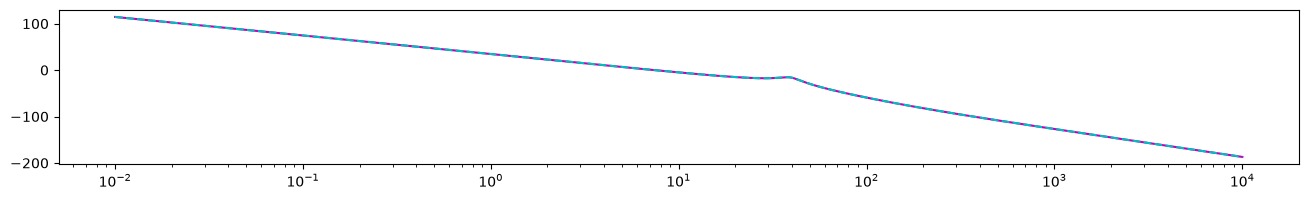

In [6]:
#Comparing the Bode plot we can see the almost perfect overlap between the original plant with that of the shifted one
m1, p1, _ = P.frequency_response(omega)
m2, p2, _ = Pc.frequency_response(omega)
plt.figure(figsize=(16, 2))
plt.semilogx(omega, 20*np.log10(m1), 'm', label=r'$\P$')
plt.semilogx(omega, 20*np.log10(m2), 'c--', label=r'$\Pc)$')

In [7]:
# Weight on S (sensitivity)
# Compute the desired closed-loop bandwidth
B3 = 3/0.6
Me = 1.5
wbe = B3
epse = 1e-2
We = ct.ss(rb.weightS(wbe,Me,epse,1))
We_inv = rb.invss(We)


In [8]:
# Weight on KS (command sensitivity)
M_u = 1000
epsu = 0.001
wbc = 1000
Wu = ct.ss(rb.weightU(wbc, M_u,epsu,1))
Wu_inv = rb.invss(Wu)

In [9]:
# Weight on T (complementary sensitivity)
M_r = pow(10.0,3.0/20)
Wt = ct.ss(ct.tf([1/M_r],[1]))
Wt_inv = rb.invss(Wt)

In [10]:
# Singular values of weights
Wu_inv_sv = rb.sigma(Wu_inv, omega)
We_inv_sv = rb.sigma(We_inv, omega)
Wt_inv_sv = rb.sigma(Wt_inv, omega)

Text(0.5, 1.0, 'Singular values of $W_t^{-1}$')

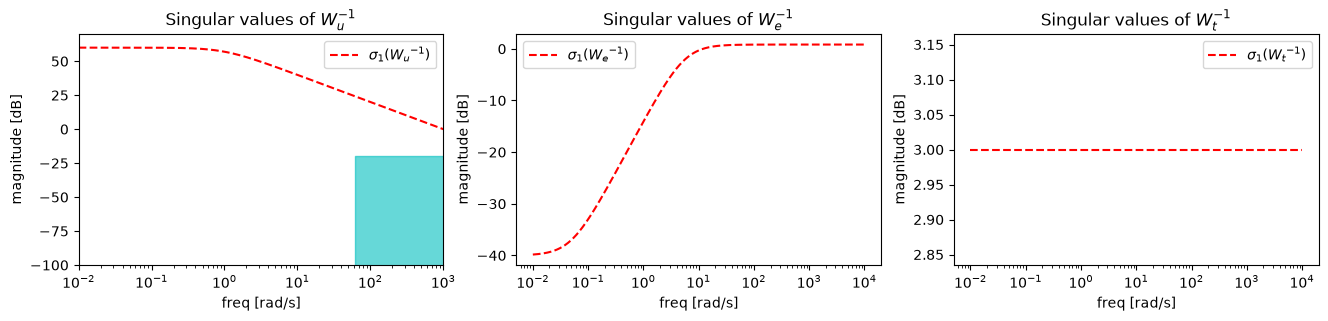

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3))

axes[0].semilogx(omega, 20*np.log10(Wu_inv_sv), 'r--', label=r'$\sigma_1({W_u}^{-1})$')
axes[0].set_ylim([-100,70])
axes[0].set_xlim([1e-2,1e3])
axes[0].set_ylabel('magnitude [dB]')
axes[0].set_xlabel('freq [rad/s]')
axes[0].fill_between(omega, -20, -120, where=(omega > 60), color='c', alpha=0.6)
axes[0].legend()
axes[0].set_title(r'Singular values of $W_u^{-1}$')

axes[1].semilogx(omega, 20*np.log10(We_inv_sv), 'r--', label=r'$\sigma_1({W_e}^{-1})$')
axes[1].set_ylabel('magnitude [dB]')
axes[1].set_xlabel('freq [rad/s]')
axes[1].legend()
axes[1].set_title(r'Singular values of $W_e^{-1}$')

axes[2].semilogx(omega, 20*np.log10(Wt_inv_sv), 'r--', label=r'$\sigma_1({W_t}^{-1})$')
axes[2].set_ylabel('magnitude [dB]')
axes[2].set_xlabel('freq [rad/s]')
axes[2].legend()
axes[2].set_title(r'Singular values of $W_t^{-1}$')

Computation of the LFT for the H-infinity problem

Compute the $H_\infty$ controller

In [12]:
# Define labels for system inputs and outputs in each block of the control loop
Pc.input_labels = ['u']
Pc.output_labels = ['yp']
We.input_labels = ['y']
We.output_labels = ['z[0]']
Wu.input_labels = ['u']
Wu.output_labels = ['z[1]']
Wt.input_labels = ['yp']
Wt.output_labels = ['z[2]']

# Negative feedback summing junction: y = r-v
fbk = ct.summing_junction(inputs=['r','-yp'], output=['y'])

# Generate the G transfer function of the LFT by interconnecting all blocks
G = ct.minreal(ct.interconnect([Pc, We, Wu, Wt, fbk],
                    inputs=['r','u'],
                    outputs=['z[0]','z[1]','z[2]','y']))
K_c, Tzw, gamma, rcond = rb.hinfsyn(G, nmeas=1, ncon=1)
display("gamma:", gamma)

0 states have been removed from the model


'gamma:'

1.1347845497174207

Observe that the optimal $\gamma$ is slightly below 1. This means that the frequency response profiles of $KS$ and $T-T_0$ will actually lie below the profiles of $W_u$ and $W_o$, respectively.

### Evaluation of performance

Text(0.5, 1.0, 'Singular values of S vs.  $\\gamma \\sigma({We}^{-1})$')

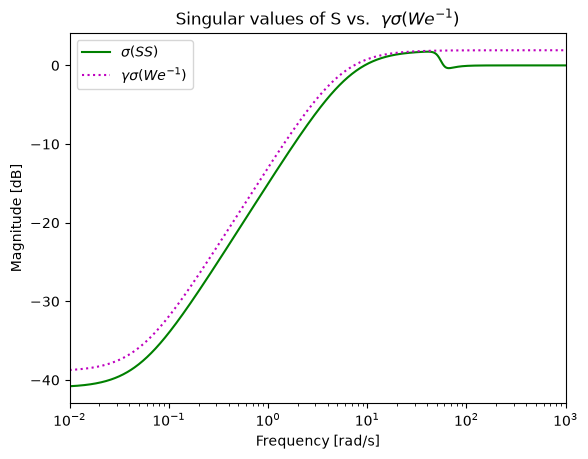

In [13]:
# S vs gamma*sigma1(We^-1)
S = ct.feedback(1, P * K_c)
S_sv = rb.sigma( S, omega)

Weinv_sv = rb.sigma(We_inv, omega) * gamma
plt.semilogx(omega, 20 * np.log10(S_sv), 'g', label=r'$\sigma(SS)$')
plt.semilogx(omega, 20 * np.log10(Weinv_sv), 'm:', label=r'$\gamma \sigma({We}^{-1})$')
plt.xlim([1e-2,1e3])
plt.ylabel('Magnitude [dB]')
plt.xlabel('Frequency [rad/s]')
plt.legend()
plt.title(r'Singular values of S vs.  $\gamma \sigma({We}^{-1})$')

Text(0.5, 1.0, 'Singular values of KS vs.  $\\gamma \\sigma({Wu}^{-1})$')

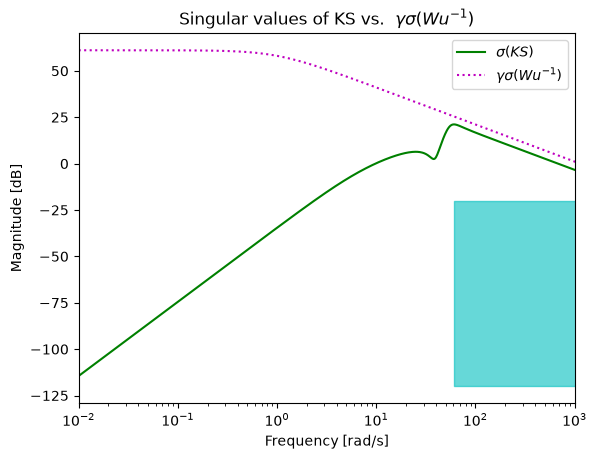

In [14]:
# KS vs gamma*sigma1(Wu^-1)
KS_sv = rb.sigma(K_c * S, omega)

Wuinv_sv = rb.sigma(Wu_inv, omega) * gamma
plt.semilogx(omega, 20 * np.log10(KS_sv), 'g', label=r'$\sigma(KS)$')
plt.semilogx(omega, 20 * np.log10(Wuinv_sv), 'm:', label=r'$\gamma \sigma({Wu}^{-1})$')
plt.fill_between(omega, -20, -120, where=(omega > 60), color='c', alpha=0.6)
plt.xlim([1e-2,1e3])
plt.ylabel('Magnitude [dB]')
plt.xlabel('Frequency [rad/s]')
plt.legend()
plt.title(r'Singular values of KS vs.  $\gamma \sigma({Wu}^{-1})$')


Text(0.5, 1.0, 'Singular values of T vs.  $\\gamma \\sigma({Wt}^{-1})$')

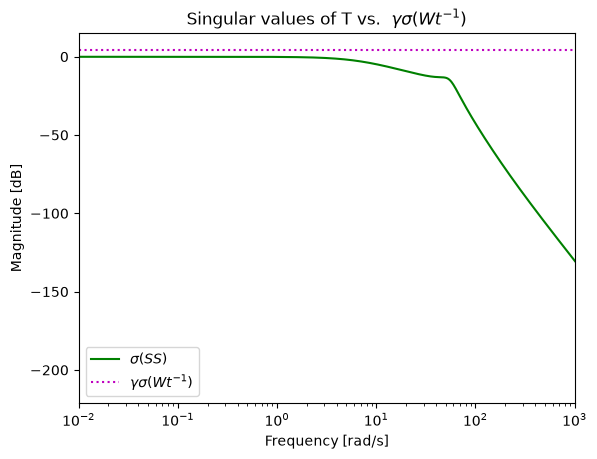

In [15]:
# T vs gamma*sigma1(Wt^-1)
T = ct.feedback(P * K_c, 1)
T_sv = rb.sigma(T, omega)

Wtinv_sv = rb.sigma(Wt_inv, omega) * gamma
plt.semilogx(omega, 20 * np.log10(T_sv), 'g', label=r'$\sigma(SS)$')
plt.semilogx(omega, 20 * np.log10(Wtinv_sv), 'm:', label=r'$\gamma \sigma({Wt}^{-1})$')
plt.xlim([1e-2,1e3])
plt.ylabel('Magnitude [dB]')
plt.xlabel('Frequency [rad/s]')
plt.legend()
plt.title(r'Singular values of T vs.  $\gamma \sigma({Wt}^{-1})$')

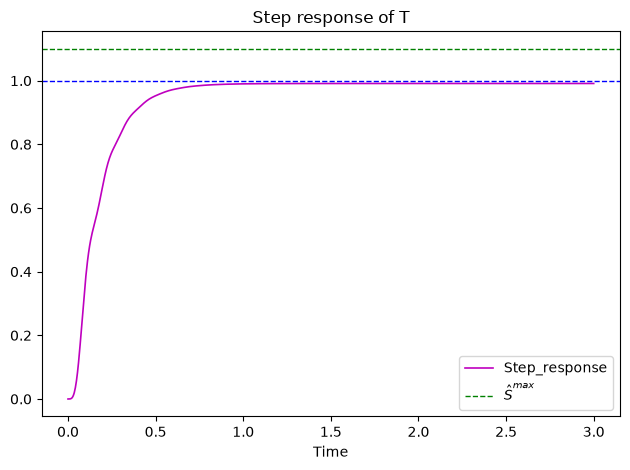

In [16]:
# Step response of T
t, step_ = ct.step_response(T, np.linspace(0, 3, 1000))
plt.plot(t, step_, label="Step_response", linewidth=1.2, color='m')
plt.axhline(y=1, color='b', linestyle='--', linewidth=1, label="")   
plt.axhline(y=1.1, color='g', linestyle='--', linewidth=1, label=r"$\hat{S}^{max}$") 
plt.xlabel("Time")
plt.title(r'Step response of T')
plt.legend()

plt.tight_layout()
plt.show()